# PCA
Aldo asked me to apply probabilistic PCA (PPCA) to hourly features as a means of dimensionality reduction. Not sure this is actually appropriate, I tried kernel PCA but dataset is way too big for that. 
Wants me to look at: how many components to explain the variance, whether patient groups cluster. Said something about passing data through autoencoders with different numbers of nodes (e.g. 1, 2, 3 etc)

In [50]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA, KernelPCA
from sklearn.preprocessing import StandardScaler

In [10]:
df_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"
df = pd.read_parquet(df_path)
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165711196,2239-11-13 13:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.800,0.0,0.000000,0.0,1.0,0,0,0,1,0
1,1165711196,2239-11-13 14:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.875,0.0,0.000000,0.0,1.0,0,0,0,1,0
2,1165711196,2239-11-13 15:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.950,0.0,0.000000,0.0,1.0,0,0,0,1,0
3,1165711196,2239-11-13 16:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.025,0.0,0.000000,0.0,1.0,0,0,0,1,0
4,1165711196,2239-11-13 17:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,0.000000,0.0,1.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.150,0.0,1.614167,0.0,1.0,1,0,0,0,0
1818559,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,1.614167,0.0,1.0,1,0,0,0,0
1818560,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,1.614167,0.0,1.0,1,0,0,0,0
1818561,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,1.614167,0.0,1.0,1,0,0,0,0


In [12]:
df.columns

Index(['encounter_id', 'time', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dexmedetomidine_med', 'fentanyl_infusion'

In [22]:
cols_to_keep = ['weight_kg', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'blood_pressure_diastolic', 'blood_pressure_mean',
       'blood_pressure_systolic', 'capillary_refill', 'heart_rate',
       'oxygen_saturation', 'respiratory_rate', 'temperature', 'vis', 'age',
       'sex', 'white', 'black', 'hispanic', 'asian', 'other']

In [16]:
# get the mortality encounters
mortality_encounters = df[df['mortality'] == 1]['encounter_id'].unique()
len(mortality_encounters)

220

In [18]:
df['mortality'].value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [17]:
# make all mortality encounters have mortality = 1
df.loc[df['encounter_id'].isin(mortality_encounters), 'mortality'] = 1
df['mortality'].value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [23]:
# separate features and labels
X = df[cols_to_keep]
y = df['mortality']

In [26]:
X

,weight_kg,alt,calcium,chloride,creatinine,crp,hematocrit,hemoglobin,neutrophil_count,neutrophil_percent,...,respiratory_rate,temperature,vis,age,sex,white,black,hispanic,asian,other
0,1.960000,10.0,8.8,105.0,0.72,15.58,49.8,15.8,4.77,63.0,...,50.00,36.800,0.0,0.000000,1.0,0,0,0,1,0
1,1.960000,10.0,8.8,105.0,0.72,15.58,49.8,15.8,4.77,63.0,...,38.00,36.875,0.0,0.000000,1.0,0,0,0,1,0
2,1.956957,10.0,8.8,105.0,0.72,15.58,49.8,15.8,4.77,63.0,...,30.00,36.950,0.0,0.000000,1.0,0,0,0,1,0
3,1.953913,10.0,8.8,105.0,0.72,15.58,49.8,15.8,4.77,63.0,...,31.00,37.025,0.0,0.000000,1.0,0,0,0,1,0
4,1.950870,10.0,8.8,105.0,0.72,15.58,49.8,15.8,4.77,63.0,...,32.00,37.100,0.0,0.000000,1.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,50.000000,23.0,7.8,114.0,0.20,125.10,29.1,9.4,5680.00,47.0,...,22.00,37.150,0.0,1.614167,1.0,1,0,0,0,0
1818559,50.000000,23.0,7.8,114.0,0.20,125.10,29.1,9.4,5680.00,47.0,...,35.50,37.100,0.0,1.614167,1.0,1,0,0,0,0
1818560,50.000000,23.0,7.8,114.0,0.20,125.10,29.1,9.4,5680.00,47.0,...,26.00,37.100,0.0,1.614167,1.0,1,0,0,0,0
1818561,50.000000,23.0,7.8,114.0,0.20,125.10,29.1,9.4,5680.00,47.0,...,26.75,37.100,0.0,1.614167,1.0,1,0,0,0,0


In [27]:
y.value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [33]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# regular PCA

In [35]:

pca = PCA(n_components=None, svd_solver='randomized', random_state=0)  # randomized = faster
pca = pca.fit(X_scaled)
Z = pca.transform(X_scaled)

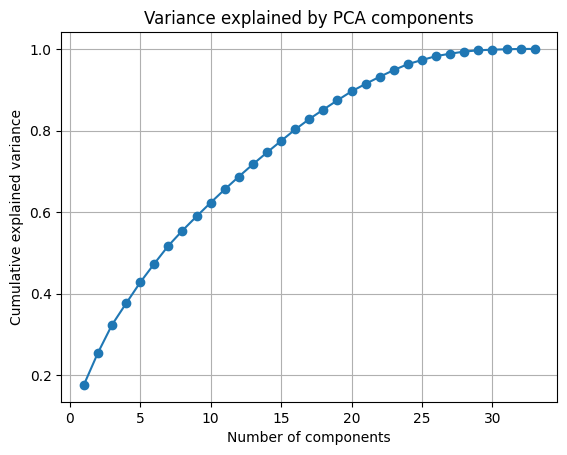

In [36]:
import numpy as np
import matplotlib.pyplot as plt

explained = np.cumsum(pca.explained_variance_ratio_)

plt.plot(np.arange(1, len(explained)+1), explained, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Variance explained by PCA components')
plt.grid(True)
plt.show()

In [38]:
Z.shape

(1818563, 33)

In [42]:
df_pca = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(Z.shape[1])])
df_pca['mortality'] = y.values 
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,mortality
0,-3.393649,1.832173,-1.294174,2.092371,-0.352203,0.585879,-1.539649,2.000570,-1.704868,-0.023802,...,-0.408232,0.552669,-1.360012e-01,-1.602889,-0.134538,-0.009813,0.258683,0.017846,1.332152e-15,0.0
1,-2.957971,1.798474,-1.289465,2.179842,-0.329015,0.669518,-1.616409,2.082751,-1.645284,-0.188406,...,-0.598366,0.379661,-1.792853e-01,-1.613337,-0.198868,-0.009731,0.259906,0.044203,1.554197e-15,0.0
2,-2.821150,1.887039,-1.354204,2.150018,-0.306906,0.644596,-1.749861,2.038985,-1.666093,-0.141421,...,-0.494220,0.398074,5.592445e-07,-1.552844,-0.180286,-0.013068,0.248362,0.079316,1.554197e-15,0.0
3,-2.803021,1.824953,-1.342946,2.148991,-0.333325,0.624390,-1.617730,2.039937,-1.685198,-0.046646,...,-0.475070,0.484686,1.663463e-01,-1.486290,-0.145265,-0.014119,0.244074,0.105989,1.443174e-15,0.0
4,-2.784892,1.762868,-1.331688,2.147964,-0.359744,0.604183,-1.485599,2.040889,-1.704304,0.048129,...,-0.455920,0.571299,3.326921e-01,-1.419735,-0.110243,-0.015170,0.239787,0.132663,1.443174e-15,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,4.221695,-0.235248,-0.375937,-0.191075,1.414782,1.409555,0.654419,-1.800827,-0.372482,-1.545890,...,0.541079,0.237904,-1.494316e-01,-0.045991,0.652848,0.013342,0.062540,0.161907,-3.330785e-15,0.0
1818559,4.245145,-0.332615,-0.426195,-0.037722,1.305683,1.068473,1.121521,-1.873852,-0.377552,-1.337926,...,0.570111,0.219931,-5.596732e-01,-0.191841,0.605152,0.016243,0.067273,0.134857,-3.774874e-15,0.0
1818560,4.871447,-0.343541,-0.556508,0.186816,1.231970,0.726203,1.372926,-1.916942,-0.333190,-1.284481,...,0.673302,0.229997,-7.261682e-01,-0.253735,0.533761,0.013256,0.073134,0.111440,-4.107941e-15,0.0
1818561,4.683096,-0.324271,-0.494907,0.124156,1.281251,0.916801,1.193667,-1.871444,-0.321547,-1.408539,...,0.551717,0.108072,-1.115913e+00,-0.399098,0.452808,0.017586,0.048601,0.239177,-3.774874e-15,0.0


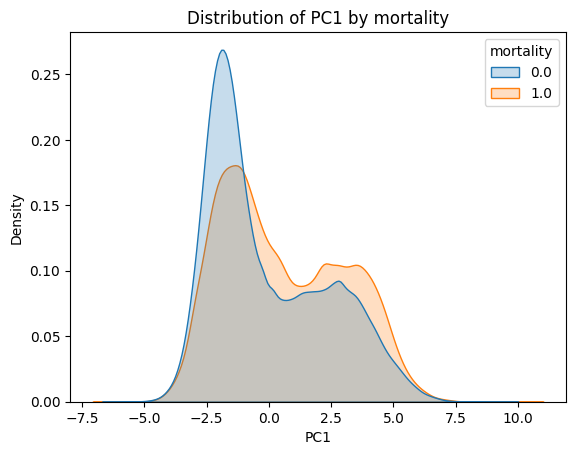

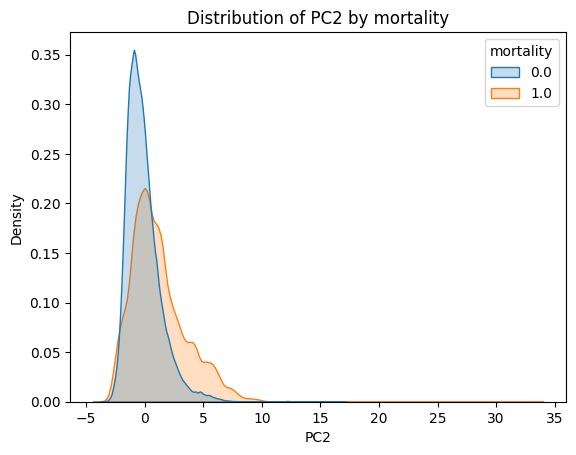

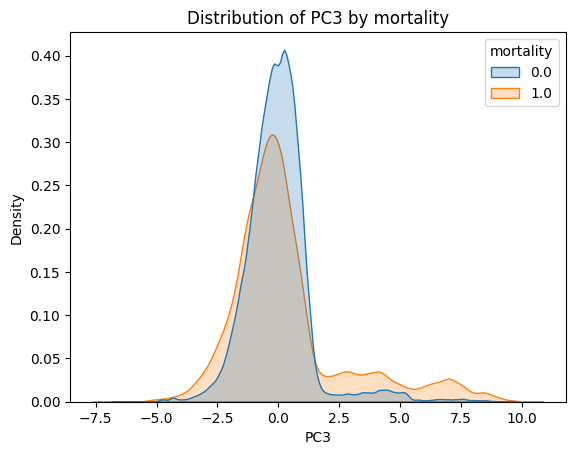

In [59]:
for i in range(3):  # first few components
    sns.kdeplot(data=df_pca, x=f'PC{i+1}', hue='mortality', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by mortality')
    plt.show()

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

X_pca = df_pca.drop(columns='mortality').values
y = df_pca['mortality'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_pca, y)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y, y_pred)
print(f"AUC using all PCA components: {auc:.3f}")

AUC using all PCA components: 0.786


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

logreg = LogisticRegression(max_iter=1000, class_weight='balanced')
logreg.fit(X_pca, y)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y, y_pred)
print(f"AUC using all PCA components (balanced weights): {auc:.3f}")

AUC using all PCA components (balanced weights): 0.792


Evaluating with 1 PCA components...
Evaluating with 2 PCA components...
Evaluating with 3 PCA components...
Evaluating with 4 PCA components...
Evaluating with 5 PCA components...
Evaluating with 6 PCA components...
Evaluating with 7 PCA components...
Evaluating with 8 PCA components...
Evaluating with 9 PCA components...
Evaluating with 10 PCA components...
Evaluating with 11 PCA components...
Evaluating with 12 PCA components...
Evaluating with 13 PCA components...
Evaluating with 14 PCA components...
Evaluating with 15 PCA components...
Evaluating with 16 PCA components...
Evaluating with 17 PCA components...
Evaluating with 18 PCA components...
Evaluating with 19 PCA components...
Evaluating with 20 PCA components...
Evaluating with 21 PCA components...
Evaluating with 22 PCA components...
Evaluating with 23 PCA components...
Evaluating with 24 PCA components...
Evaluating with 25 PCA components...
Evaluating with 26 PCA components...
Evaluating with 27 PCA components...
Evaluating

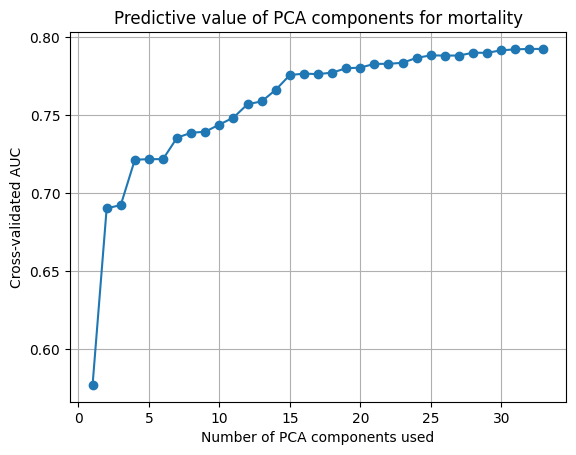

In [58]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

aucs = []
for k in range(1, Z.shape[1] + 1):  # from 1 to all 33 components
    print(f"Evaluating with {k} PCA components...")
    scores = cross_val_score(
        LogisticRegression(max_iter=1000, class_weight='balanced'),
        Z[:, :k], y,
        cv=cv, scoring='roc_auc'
    )
    aucs.append(scores.mean())

plt.plot(range(1, len(aucs)+1), aucs, marker='o')
plt.xlabel('Number of PCA components used')
plt.ylabel('Cross-validated AUC')
plt.title('Predictive value of PCA components for mortality')
plt.grid(True)
plt.show()

In [72]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=[f for f in X.columns if f not in ['mortality']],
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

top_pcs = range(1, 33)  # top 7 predictive components
for pc in top_pcs:
    print(f"\nTop features for PC{pc}:")
    print(loadings[f'PC{pc}'].sort_values(key=abs, ascending=False).head(10))


Top features for PC1:
age                         0.353303
blood_pressure_systolic     0.343632
weight_kg                   0.340465
blood_pressure_mean         0.318484
heart_rate                 -0.307491
blood_pressure_diastolic    0.307254
respiratory_rate           -0.287403
calcium                    -0.233597
potassium                  -0.196774
random_glucose              0.183517
Name: PC1, dtype: float64

Top features for PC2:
neutrophil_count               0.383115
pupil_reaction_right_binary    0.366384
pupil_reaction_left_binary     0.361633
white_blood_cell_count         0.331998
neutrophil_percent             0.319625
hematocrit                     0.278172
hemoglobin                     0.268457
fixed_pupils                   0.262477
creatinine                     0.174587
oxygen_saturation             -0.160296
Name: PC2, dtype: float64

Top features for PC3:
pupil_reaction_left_binary     0.480398
pupil_reaction_right_binary    0.476552
fixed_pupils                 

In [67]:
k_opt = 7  # will use top 7 components
logreg = LogisticRegression(max_iter=1000, class_weight='balanced')
logreg.fit(Z[:, :k_opt], y)

# Construct continuous score
df['health_score'] = X_pca[:, :k_opt] @ logreg.coef_[0][:k_opt]

In [68]:
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,vis,age,mortality,sex,white,black,hispanic,asian,other,health_score
0,1165711196,2239-11-13 13:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.000000,0.0,1.0,0,0,0,1,0,-0.071501
1,1165711196,2239-11-13 14:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.000000,0.0,1.0,0,0,0,1,0,-0.024350
2,1165711196,2239-11-13 15:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.000000,0.0,1.0,0,0,0,1,0,0.069060
3,1165711196,2239-11-13 16:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.000000,0.0,1.0,0,0,0,1,0,0.012628
4,1165711196,2239-11-13 17:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.000000,0.0,1.0,0,0,0,1,0,-0.043804
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,1.614167,0.0,1.0,1,0,0,0,0,0.483177
1818559,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,1.614167,0.0,1.0,1,0,0,0,0,0.271391
1818560,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,1.614167,0.0,1.0,1,0,0,0,0,0.211574
1818561,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,1.614167,0.0,1.0,1,0,0,0,0,0.265284


In [70]:
import numpy as np
from sklearn.metrics import roc_auc_score

for i in range(33):
    auc = roc_auc_score(y, Z[:, i])
    print(f"PC{i+1}: AUC={auc:.3f}")

PC1: AUC=0.577
PC2: AUC=0.672
PC3: AUC=0.492
PC4: AUC=0.397
PC5: AUC=0.519
PC6: AUC=0.481
PC7: AUC=0.424
PC8: AUC=0.547
PC9: AUC=0.497
PC10: AUC=0.532
PC11: AUC=0.539
PC12: AUC=0.527
PC13: AUC=0.561
PC14: AUC=0.515
PC15: AUC=0.418
PC16: AUC=0.509
PC17: AUC=0.524
PC18: AUC=0.488
PC19: AUC=0.548
PC20: AUC=0.516
PC21: AUC=0.581
PC22: AUC=0.497
PC23: AUC=0.512
PC24: AUC=0.452
PC25: AUC=0.479
PC26: AUC=0.519
PC27: AUC=0.493
PC28: AUC=0.565
PC29: AUC=0.443
PC30: AUC=0.380
PC31: AUC=0.479
PC32: AUC=0.512
PC33: AUC=0.545


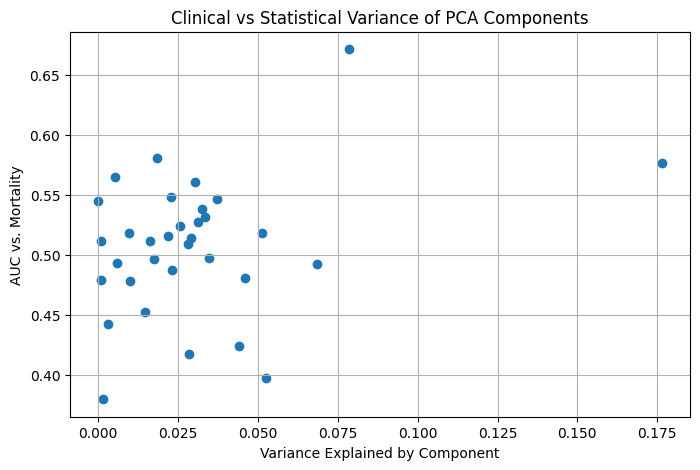

In [71]:
aucs = [roc_auc_score(y, Z[:, i]) for i in range(Z.shape[1])]
explained = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.scatter(explained, aucs)
plt.xlabel('Variance Explained by Component')
plt.ylabel('AUC vs. Mortality')
plt.title('Clinical vs Statistical Variance of PCA Components')
plt.grid(True)
plt.show()

In [73]:
corr = np.corrcoef(Z[:, 1], Z[:, 20])[0, 1]  # PC indices start at 0
print(f"Correlation between PC2 and PC21: {corr:.3f}")

Correlation between PC2 and PC21: 0.000


In [76]:
common_feats

Index(['weight_kg', 'alt', 'calcium', 'chloride', 'creatinine', 'crp',
       'hematocrit', 'hemoglobin', 'neutrophil_count', 'neutrophil_percent',
       'potassium', 'random_glucose', 'sodium', 'white_blood_cell_count',
       'fixed_pupils', 'pupil_reaction_left_binary',
       'pupil_reaction_right_binary', 'blood_pressure_diastolic',
       'blood_pressure_mean', 'blood_pressure_systolic', 'capillary_refill',
       'heart_rate', 'oxygen_saturation', 'respiratory_rate', 'temperature',
       'vis', 'age', 'sex', 'white', 'black', 'hispanic', 'asian', 'other'],
      dtype='object')

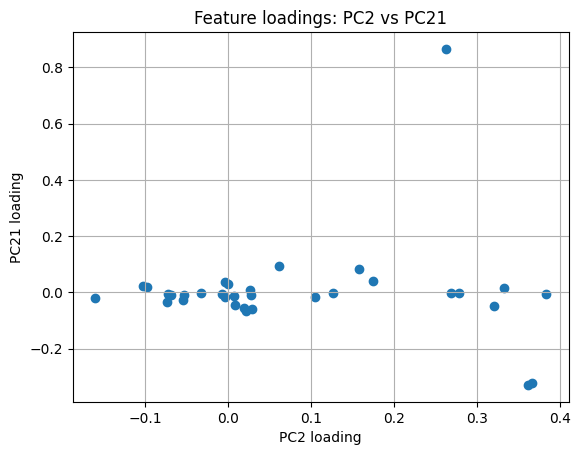

In [74]:
common_feats = loadings.index.intersection(loadings.index)
plt.scatter(loadings['PC2'], loadings['PC21'])
plt.xlabel('PC2 loading')
plt.ylabel('PC21 loading')
plt.title('Feature loadings: PC2 vs PC21')
plt.grid(True)

In [55]:
Z.shape[1] + 1

34

In [53]:
Z

array([[-3.39364902e+00,  1.83217276e+00, -1.29417382e+00, ...,
         2.58682522e-01,  1.78460384e-02,  1.33215219e-15],
       [-2.95797069e+00,  1.79847435e+00, -1.28946550e+00, ...,
         2.59905867e-01,  4.42027927e-02,  1.55419680e-15],
       [-2.82114973e+00,  1.88703857e+00, -1.35420370e+00, ...,
         2.48361930e-01,  7.93159836e-02,  1.55419680e-15],
       ...,
       [ 4.87144716e+00, -3.43541091e-01, -5.56507829e-01, ...,
         7.31340610e-02,  1.11440451e-01, -4.10794063e-15],
       [ 4.68309616e+00, -3.24270515e-01, -4.94906583e-01, ...,
         4.86011849e-02,  2.39177130e-01, -3.77487372e-15],
       [ 3.99204605e+00, -2.11989604e-01, -3.16604078e-01, ...,
         7.68901691e-02,  9.13209328e-02, -3.21976221e-15]],
      shape=(1818563, 33))

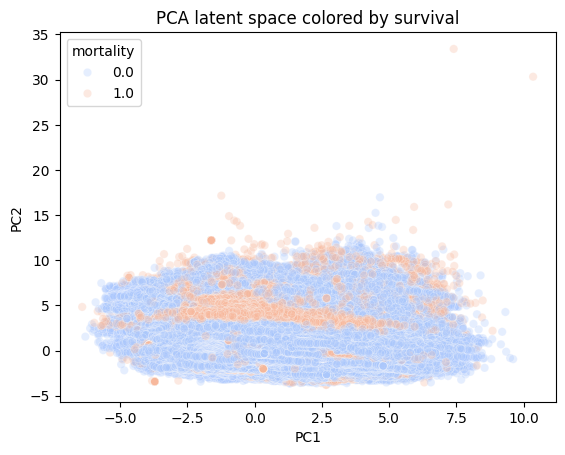

In [52]:
sns.scatterplot(
    data=df_pca, x='PC1', y='PC2', hue='mortality',
    alpha=0.3, palette='coolwarm'
)
plt.title('PCA latent space colored by survival')
plt.show()

# kernel PCA

In [51]:
kernel_pca = KernelPCA(
    n_components=None, kernel="rbf", gamma=10, fit_inverse_transform=True, alpha=0.1
)
kernel_pca = kernel_pca.fit(X_scaled)
kernel_Z = kernel_pca.transform(X_scaled)

MemoryError: Unable to allocate 24.1 TiB for an array with shape (1818563, 1818563) and data type float64

In [29]:
# Fit PPCA (using Factor Analysis as an equivalent)
ppca = FactorAnalysis(n_components=2, random_state=0)  # e.g., 2 latent dims
Z = ppca.fit_transform(X_scaled)

KeyboardInterrupt: 